In [5]:
import pandas as pd

In [6]:
df = pd.read_csv(
    "../data/processed/online_retail_clean.csv",
    parse_dates=["InvoiceDate"]
)

In [7]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  int64         
 1   StockCode    392692 non-null  str           
 2   Description  392692 non-null  str           
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  int64         
 7   Country      392692 non-null  str           
 8   TotalPrice   392692 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(3), str(3)
memory usage: 43.8 MB


In [8]:
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

analysis_date

Timestamp('2011-12-10 12:50:00')

In [9]:
last_purchase = (
    df.groupby("CustomerID")["InvoiceDate"]
      .max()
)

In [8]:
last_purchase 

CustomerID
12346   2011-01-18 10:01:00
12347   2011-12-07 15:52:00
12348   2011-09-25 13:13:00
12349   2011-11-21 09:51:00
12350   2011-02-02 16:01:00
                ...        
18280   2011-03-07 09:52:00
18281   2011-06-12 10:53:00
18282   2011-12-02 11:43:00
18283   2011-12-06 12:02:00
18287   2011-10-28 09:29:00
Name: InvoiceDate, Length: 4338, dtype: datetime64[us]

In [10]:
recency = analysis_date - last_purchase

recency.head()

CustomerID
12346   326 days 02:49:00
12347     2 days 20:58:00
12348    75 days 23:37:00
12349    19 days 02:59:00
12350   310 days 20:49:00
Name: InvoiceDate, dtype: timedelta64[us]

In [11]:
recency = recency.dt.days

In [12]:
recency.head()

CustomerID
12346    326
12347      2
12348     75
12349     19
12350    310
Name: InvoiceDate, dtype: int64

In [16]:
frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()

frequency.head()

CustomerID
12346    1
12347    7
12348    4
12349    1
12350    1
Name: InvoiceNo, dtype: int64

In [13]:
monetary  = (df.groupby("CustomerID")["TotalPrice"].sum())

In [14]:
monetary.head()

CustomerID
12346    77183.60
12347     4310.00
12348     1797.24
12349     1757.55
12350      334.40
Name: TotalPrice, dtype: float64

In [17]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

In [21]:
rfm.head(100)

,Recency,Frequency,Monetary,R_Score
CustomerID,,,,
12346,326,1,77183.60,1
12347,2,7,4310.00,4
12348,75,4,1797.24,2
12349,19,1,1757.55,3
12350,310,1,334.40,1
...,...,...,...,...
12462,19,2,1189.59,3
12463,53,4,1344.78,2
12464,10,8,1212.05,4


In [18]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [19]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
)

In [20]:
rfm[["Recency", "R_Score"]].head(10)


,Recency,R_Score
CustomerID,,
12346,326,1
12347,2,4
12348,75,2
12349,19,3
12350,310,1
12352,36,3
12353,204,1
12354,232,1
12355,214,1


In [22]:
rfm["F_Score"] = pd.qcut(rfm["Frequency"], q=4, labels=[1,2,3,4])

ValueError: Bin edges must be unique: Index([1.0, 1.0, 2.0, 5.0, 209.0], dtype='float64', name='Frequency').
You can drop duplicate edges by setting the 'duplicates' kwarg

In [24]:
rfm["Frequency"].value_counts().sort_index().head(10)

Frequency
1     1493
2      835
3      508
4      388
5      242
6      172
7      143
8       98
9       68
10      54
Name: count, dtype: int64

In [23]:
rfm["F_Score"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 2, 5, float("inf")],
    labels=[1, 2, 3, 4]
)

In [24]:
rfm[["Frequency", "F_Score"]].head(10)

,Frequency,F_Score
CustomerID,,
12346,1,1
12347,7,4
12348,4,3
12349,1,1
12350,1,1
12352,8,4
12353,1,1
12354,1,1
12355,1,1


In [25]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    q=4,
    labels=[1, 2, 3, 4]
)

In [26]:
rfm[["Monetary", "M_Score"]].head(10)

,Monetary,M_Score
CustomerID,,
12346,77183.60,4
12347,4310.00,4
12348,1797.24,4
12349,1757.55,4
12350,334.40,2
12352,2506.04,4
12353,89.00,1
12354,1079.40,3
12355,459.40,2


In [27]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

In [28]:
rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]].head(10)

,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,
12346,1,1,4,114
12347,4,4,4,444
12348,2,3,4,234
12349,3,1,4,314
12350,1,1,2,112
12352,3,4,4,344
12353,1,1,1,111
12354,1,1,3,113
12355,1,1,2,112


In [29]:
def assign_segment(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Champions"

In [33]:
def assign_segment(row):

    if (
        row["R_Score"] >= 3
        and row["F_Score"] >= 3
        and row["M_Score"] >= 3
    ):
        return "Champions"

    elif (
        row["R_Score"] <= 2
        and row["F_Score"] >= 3
        and row["M_Score"] >= 3
    ):
        return "At Risk"

    elif (
        row["R_Score"] >= 2
        and row["F_Score"] >= 3
        and row["M_Score"] >= 2
    ):
        return "Loyal Customers"

    elif (
        row["R_Score"] >= 3
        and row["F_Score"] >= 2
        and row["M_Score"] >= 2
    ):
        return "Potential Loyalists"

    elif (
        row["R_Score"] == 4
        and row["F_Score"] == 1
    ):
        return "New Customers"

    elif (
        row["R_Score"] == 1
        and row["F_Score"] <= 2
        and row["M_Score"] <= 2
    ):
        return "Lost Customers"

    else:
        return "Others"

In [34]:
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

In [35]:
rfm["Segment"].value_counts()

Segment
Champions              1301
Others                 1195
Lost Customers          825
At Risk                 424
Potential Loyalists     289
Loyal Customers         201
New Customers           103
Name: count, dtype: int64

In [37]:
rfm["Segment"].value_counts(dropna=False)

Segment
Champions              1301
Others                 1195
Lost Customers          825
At Risk                 424
Potential Loyalists     289
Loyal Customers         201
New Customers           103
Name: count, dtype: int64

NameError: name 'plt' is not defined

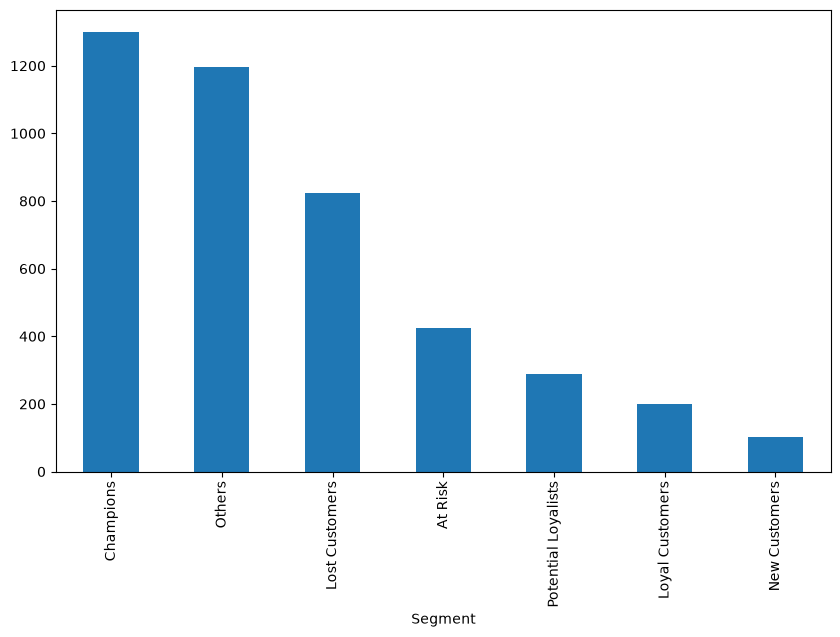

In [44]:
segment_counts = rfm["Segment"].value_counts()

segment_counts.plot(kind="bar", figsize=(10, 6))

plt.title("Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346,326,1,77183.60,1,1,4,114,Others
12347,2,7,4310.00,4,4,4,444,Champions
12348,75,4,1797.24,2,3,4,234,At Risk
12349,19,1,1757.55,3,1,4,314,Others
12350,310,1,334.40,1,1,2,112,Lost Customers


In [46]:
rfm.info()

<class 'pandas.DataFrame'>
Index: 4338 entries, 12346 to 18287
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   Recency    4338 non-null   int64   
 1   Frequency  4338 non-null   int64   
 2   Monetary   4338 non-null   float64 
 3   R_Score    4338 non-null   category
 4   F_Score    4338 non-null   category
 5   M_Score    4338 non-null   category
 6   RFM_Score  4338 non-null   str     
 7   Segment    4338 non-null   str     
dtypes: category(3), float64(1), int64(2), str(2)
memory usage: 271.1 KB


In [47]:
rfm.to_csv(
    "../data/processed/rfm_customer_segments.csv",
    index=True
)

In [48]:
check_rfm = pd.read_csv(
    "../data/processed/rfm_customer_segments.csv"
)

check_rfm.head()


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,4,114,Others
1,12347,2,7,4310.00,4,4,4,444,Champions
2,12348,75,4,1797.24,2,3,4,234,At Risk
3,12349,19,1,1757.55,3,1,4,314,Others
4,12350,310,1,334.40,1,1,2,112,Lost Customers
